# **Team**: **Sagar Parajuli - CS26BTKMU11003**
#### Please also see github for any additional comments(README.md summary) or summary of all assignments as a whole
>https://github.com/SagarP-0/LO-Assignments/

# Maximum Matching in a Bipartite Graph
**Linear Optimisation, Assignment 3**

- Maximum matching is written as an ILP with one binary variable per edge
- The binary constraints are relaxed to `y_e >= 0`
- The LP is solved with the geometric simplex method from Assignment 1
- The optimal LP vertex is converted to a binary matching with the threshold 0.5

## 1. Imports and configuration

- `CSV_PATH`: input edge list (two columns, no header)
- If the file is missing, a sample graph is created
- Tolerances are the same as in Assignment 1
- The simplex routine maximises `c^T y` subject to `A y <= b` with `rank(A) = n`

In [ ]:
CSV_PATH = "graph_edges.csv"

In [ ]:
import csv
import itertools
import os
import re
from collections import deque
from dataclasses import dataclass, field

import numpy as np

np.set_printoptions(precision=4, suppress=True)

# tolerances
TOL_FEAS = 1e-8      # feasibility and tight constraints
TOL_RANK = 1e-9      # rank (relative to the largest singular value)
TOL_IMPROVE = 1e-9   # c.d must be larger than this to count as improving
TOL_DIR = 1e-9       # sign tests on direction vectors
TOL_STEP = 1e-12     # smallest step treated as non-zero
TOL_SAME = 1e-7      # two points or directions are the same

THRESHOLD = 0.5     # rounding threshold for LP values
TOL_CHECK = 1e-6    # tolerance for integrality and equality checks


def stop(message):
    """Print an error message and halt the notebook."""
    print("Error:", message)
    raise SystemExit


def verdict(ok):
    return "PASS" if ok else "FAIL"

## 2. CSV input and graph construction

Input rules
- Each row is one edge with exactly two non-empty fields
- No header row
- Fields are stripped of spaces
- Vertex ids are integers if every field is an integer, otherwise strings
- Blank lines are skipped

Validation
- Malformed row (not two non-empty fields): error
- Self-loop `(v, v)`: error, since the graph is then not bipartite
- Duplicate edge, including a reversed copy `(v, u)`: kept once, count reported

In [ ]:
if not os.path.exists(CSV_PATH):
    with open(CSV_PATH, "w") as f:
        f.write("A,B\nA,C\nB,D\nC,D\nD,E\nF,G\nA,G\nH,B\n")
    print(f"Created sample file {CSV_PATH}")

In [ ]:
def read_edges(path):
    """Read the edge list. Returns (vertices, edges, number_of_duplicates_removed)."""
    if not os.path.isfile(path):
        stop(f"File '{path}' not found.")
    rows = []
    with open(path, newline="") as f:
        for line_no, row in enumerate(csv.reader(f), start=1):
            if not row or all(t.strip() == "" for t in row):
                continue
            if len(row) != 2 or any(t.strip() == "" for t in row):
                stop(f"Row {line_no} is malformed: expected 2 non-empty fields, found {row}.")
            rows.append((row[0].strip(), row[1].strip(), line_no))
    if not rows:
        stop("The file contains no edges.")

    tokens = [t for u, v, _ in rows for t in (u, v)]
    if all(re.fullmatch(r"-?\d+", t) and str(int(t)) == t for t in tokens):
        rows = [(int(u), int(v), k) for u, v, k in rows]

    edges, seen, duplicates = [], set(), 0
    for u, v, line_no in rows:
        if u == v:
            stop(f"Row {line_no} is a self-loop ({u}, {v}); the graph is not bipartite.")
        key = frozenset((u, v))
        if key in seen:
            duplicates += 1
            continue
        seen.add(key)
        edges.append((u, v))
    vertices = sorted({t for e in edges for t in e})
    return vertices, edges, duplicates

In [ ]:
vertices, edges, n_dup = read_edges(CSV_PATH)
print(f"Vertices ({len(vertices)}): {', '.join(map(str, vertices))}")
print(f"Edges    ({len(edges)}): " + ", ".join(f"({u},{v})" for u, v in edges))
if n_dup:
    print(f"Duplicate edges removed: {n_dup}")

Vertices (8): A, B, C, D, E, F, G, H
Edges    (8): (A,B), (A,C), (B,D), (C,D), (D,E), (F,G), (A,G), (H,B)


## 3. Bipartition detection (BFS)

- Colour each connected component with two colours using BFS
- A start vertex gets colour 0, its neighbours colour 1, and so on
- If an edge joins two vertices of the same colour, the graph is not bipartite
- Colour 0 gives `U`, colour 1 gives `V`

In [ ]:
def bipartition(vertices, edges):
    """Two-colour the graph by BFS. Returns (U, V), or stops if the graph is not bipartite."""
    adj = {v: [] for v in vertices}
    for u, v in edges:
        adj[u].append(v)
        adj[v].append(u)
    colour = {}
    for start in vertices:
        if start in colour:
            continue
        colour[start] = 0
        queue = deque([start])
        while queue:
            u = queue.popleft()
            for w in adj[u]:
                if w not in colour:
                    colour[w] = 1 - colour[u]
                    queue.append(w)
                elif colour[w] == colour[u]:
                    stop(f"The graph is not bipartite: edge ({u}, {w}) joins two vertices "
                         f"of the same colour. Bipartite methods are not applied.")
    U = [v for v in vertices if colour[v] == 0]
    V = [v for v in vertices if colour[v] == 1]
    return U, V

In [ ]:
U, V = bipartition(vertices, edges)
print("The graph is bipartite.")
print(f"U = {{{', '.join(map(str, U))}}}")
print(f"V = {{{', '.join(map(str, V))}}}")

The graph is bipartite.
U = {A, D, F, H}
V = {B, C, E, G}


## 4. Maximum matching ILP formulation

Variables: $y_e \in \{0,1\}$ for each edge $e \in E$, with $y_e = 1$ if $e$ is in the matching.

$$\max z = \sum_{e \in E} y_e$$

$$\text{s.t.}\quad \sum_{e \ni v} y_e \le 1 \quad \forall v \in U \cup V, \qquad y_e \in \{0,1\}$$

- A matching has no two edges with a common endpoint
- So at most one selected edge can touch any vertex $v$
- The sum of $y_e$ over the edges at $v$ counts the selected edges at $v$, so it must be at most 1

In [ ]:
def edge_name(e):
    return f"y({e[0]},{e[1]})"


def print_vertex_constraints(vertices, edges):
    lines = [(" + ".join(edge_name(e) for e in edges if v in e) + " ≤ 1", f"(vertex {v})")
             for v in vertices]
    width = max(len(l) for l, _ in lines) + 4
    for left, right in lines:
        print(f"    {left:<{width}}{right}")


def print_ilp(vertices, edges):
    print("Maximum matching ILP")
    print("  Variables: y_e in {0,1} for every edge e; y_e = 1 if e is in the matching\n")
    print("  maximise   z = " + " + ".join(edge_name(e) for e in edges))
    print("  subject to")
    print_vertex_constraints(vertices, edges)
    print("    y_e ∈ {0,1}  for " + ", ".join(edge_name(e) for e in edges))

In [ ]:
print_ilp(vertices, edges)

Maximum matching ILP
  Variables: y_e in {0,1} for every edge e; y_e = 1 if e is in the matching

  maximise   z = y(A,B) + y(A,C) + y(B,D) + y(C,D) + y(D,E) + y(F,G) + y(A,G) + y(H,B)
  subject to
    y(A,B) + y(A,C) + y(A,G) ≤ 1    (vertex A)
    y(A,B) + y(B,D) + y(H,B) ≤ 1    (vertex B)
    y(A,C) + y(C,D) ≤ 1             (vertex C)
    y(B,D) + y(C,D) + y(D,E) ≤ 1    (vertex D)
    y(D,E) ≤ 1                      (vertex E)
    y(F,G) ≤ 1                      (vertex F)
    y(F,G) + y(A,G) ≤ 1             (vertex G)
    y(H,B) ≤ 1                      (vertex H)
    y_e ∈ {0,1}  for y(A,B), y(A,C), y(B,D), y(C,D), y(D,E), y(F,G), y(A,G), y(H,B)


## 5. LP relaxation

Replace $y_e \in \{0,1\}$ by $y_e \ge 0$.

- The bound $y_e \le 1$ is not needed: the constraint of any endpoint of $e$ already gives $y_e \le 1$
- Variables: one per edge, `n = |E|`
- Rows of `A y <= b` for the simplex routine:
  - vertex `v`: sum of `y_e` over edges at `v` `<= 1`
  - non-negativity: `-y_e <= 0`
- Objective: `max sum(y_e)`
- The `-y_e <= 0` rows give `rank(A) = n`

In [ ]:
def build_matching_lp(vertices, edges):
    """Matrices (c, A, b) of the relaxed matching LP in the form max c.y, A y <= b."""
    n = len(edges)
    rows, rhs = [], []
    for v in vertices:
        rows.append(np.array([1.0 if v in e else 0.0 for e in edges]))
        rhs.append(1.0)
    rows += list(-np.eye(n))
    rhs += [0.0] * n
    return np.ones(n), np.array(rows), np.array(rhs)


def print_relaxed_lp(vertices, edges):
    print("Relaxed matching LP")
    print("  maximise   z = " + " + ".join(edge_name(e) for e in edges))
    print("  subject to")
    print_vertex_constraints(vertices, edges)
    print("    y_e ≥ 0   for " + ", ".join(edge_name(e) for e in edges))

In [ ]:
print_relaxed_lp(vertices, edges)
c_m, A_m, b_m = build_matching_lp(vertices, edges)
print(f"\nSimplex form: n = {A_m.shape[1]} variables, m = {A_m.shape[0]} constraints")

Relaxed matching LP
  maximise   z = y(A,B) + y(A,C) + y(B,D) + y(C,D) + y(D,E) + y(F,G) + y(A,G) + y(H,B)
  subject to
    y(A,B) + y(A,C) + y(A,G) ≤ 1    (vertex A)
    y(A,B) + y(B,D) + y(H,B) ≤ 1    (vertex B)
    y(A,C) + y(C,D) ≤ 1             (vertex C)
    y(B,D) + y(C,D) + y(D,E) ≤ 1    (vertex D)
    y(D,E) ≤ 1                      (vertex E)
    y(F,G) ≤ 1                      (vertex F)
    y(F,G) + y(A,G) ≤ 1             (vertex G)
    y(H,B) ≤ 1                      (vertex H)
    y_e ≥ 0   for y(A,B), y(A,C), y(B,D), y(C,D), y(D,E), y(F,G), y(A,G), y(H,B)

Simplex form: n = 8 variables, m = 16 constraints


## 6. Simplex solution

- The routines below are the geometric simplex from Assignment 1, unchanged
- Initial vertex: enumeration of `n` independent tight constraints
- Each iteration moves along an improving edge to the next vertex
- Enumeration cost grows like `C(m, n)`, so the method suits small graphs

In [ ]:
def numerical_rank(M, tol=TOL_RANK):
    M = np.atleast_2d(M)
    if M.size == 0:
        return 0
    s = np.linalg.svd(M, compute_uv=False)
    return int(np.sum(s > tol * max(1.0, s[0])))


def is_feasible(A, b, x, tol=TOL_FEAS):
    return bool(np.all(A @ x - b <= tol * (1 + np.abs(b))))


def tight_rows(A, b, x, tol=TOL_FEAS):
    return np.flatnonzero(np.abs(A @ x - b) <= tol * (1 + np.abs(b)))


def is_vertex(A, b, x):
    return is_feasible(A, b, x) and numerical_rank(A[tight_rows(A, b, x)]) == A.shape[1]


def fmt(x):
    v = np.asarray(x, float)
    v = np.where(np.abs(v) < 1e-9, 0.0, v)      # hide round-off such as -3e-16
    return "[" + ", ".join(f"{t:.4g}" for t in v) + "]"

In [ ]:
def find_initial_vertex(A, b, max_sets=2_000_000):
    """Return (vertex, status) with status 'found', 'infeasible' or 'undetermined'."""
    m, n = A.shape
    for count, rows in enumerate(itertools.combinations(range(m), n)):
        if count >= max_sets:
            return None, "undetermined"
        A_I = A[list(rows)]
        if numerical_rank(A_I) < n:
            continue
        x = np.linalg.solve(A_I, b[list(rows)])
        if is_feasible(A, b, x):
            return x, "found"
    return None, "infeasible"

In [ ]:
@dataclass
class Result:
    status: str          # optimal, unbounded, infeasible, undetermined, cycle, max_iterations, numerical_failure
    message: str = ""
    x: np.ndarray = None
    z: float = None
    path: list = field(default_factory=list)
    ray: np.ndarray = None
    start: np.ndarray = None


def edge_directions(A, tight):
    """Unit directions of the edges leaving the vertex with tight rows `tight`."""
    n = A.shape[1]
    A_T = A[tight]
    norms = np.linalg.norm(A_T, axis=1)
    found = []
    for J in itertools.combinations(range(len(tight)), n - 1):
        A_J = A_T[list(J)]
        if numerical_rank(A_J) != n - 1:
            continue
        # last right singular vector spans the null space of A_J
        d = np.array([1.0]) if n == 1 else np.linalg.svd(A_J)[2][-1]
        for sign in (1.0, -1.0):
            cand = sign * d
            if np.all(A_T @ cand <= TOL_DIR * norms):
                if not any(np.allclose(cand, e, atol=TOL_SAME) for e in found):
                    found.append(cand)
    return found


def ratio_test(A, b, x, d):
    """Largest step t with A(x + t d) <= b. Returns np.inf if no row blocks."""
    Ad = A @ d
    rows = np.flatnonzero(Ad > TOL_DIR * np.linalg.norm(A, axis=1))
    if rows.size == 0:
        return np.inf
    slack = np.maximum(b - A @ x, 0.0)
    return float(np.min(slack[rows] / Ad[rows]))


def geometric_simplex(A, b, c, x0, max_iter=1000):
    """Maximise c.x over A x <= b, moving along improving edges from vertex x0."""
    n = A.shape[1]
    x = np.array(x0, float)
    start = x.copy()
    path, seen = [], set()
    scale = 1 + np.linalg.norm(c)

    def stop(status, msg, pt):
        return Result(status, msg, pt, float(c @ pt), path, None, start)

    if not is_vertex(A, b, x):
        return stop("numerical_failure", "Starting point is not a vertex.", x)

    for it in range(max_iter + 1):
        z = float(c @ x)
        tight = tight_rows(A, b, x)
        path.append({"iter": it, "x": x.copy(), "z": z, "tight": tight.tolist()})
        seen.add(tuple(np.round(x, 6) + 0.0))

        # improving edges at this vertex
        moves = []
        for d in edge_directions(A, tight):
            if c @ d > TOL_IMPROVE * scale:
                t = ratio_test(A, b, x, d)
                if np.isinf(t):
                    r = stop("unbounded", "Improving ray with no blocking constraint.", x)
                    r.ray = d
                    return r
                moves.append((c @ d, t, d))

        if not moves:
            return Result("optimal", "", x.copy(), z, path, None, start)

        rate, t, d = max(moves, key=lambda m: m[0])
        if t <= TOL_STEP:
            return stop("numerical_failure", "Zero-length step.", x)

        # move to the next vertex and clean it up with the tight system
        x_new = x + t * d
        tight_new = tight_rows(A, b, x_new)
        if numerical_rank(A[tight_new]) != n:
            return stop("numerical_failure", "New point is not a vertex.", x_new)
        x_new = np.linalg.lstsq(A[tight_new], b[tight_new], rcond=None)[0]
        z_new = float(c @ x_new)
        if not is_feasible(A, b, x_new):
            return stop("numerical_failure", "New vertex is infeasible.", x_new)
        if abs(z_new - (z + t * rate)) > 1e-6 * (1 + abs(z_new)):
            return stop("numerical_failure", "Objective change does not match t * (c.d).", x_new)
        if tuple(np.round(x_new, 6) + 0.0) in seen:
            return stop("cycle", "Vertex repeated.", x_new)
        x = x_new

    return stop("max_iterations", f"Reached {max_iter} iterations.", x)


def solve_lp(c, A, b, x0=None, max_iter=1000):
    """Find a starting vertex (unless given) and run the geometric simplex."""
    c, A, b = (np.asarray(v, float) for v in (c, A, b))
    if x0 is None:
        x0, status = find_initial_vertex(A, b)
        if status == "infeasible":
            return Result("infeasible")
        if status == "undetermined":
            return Result("undetermined", "Search limit reached before a vertex was found.")
    return geometric_simplex(A, b, c, np.asarray(x0, float), max_iter)

`run_simplex` calls the routines above and prints the visited vertices

- `sign = +1` for a maximisation problem
- The run stops with a message if the solver does not return `optimal`

In [ ]:
def run_simplex(c, A, b, names, sign):
    """Solve max c.x s.t. A x <= b and print the vertices visited."""
    if numerical_rank(A) != A.shape[1]:
        stop("rank(A) < n, so the simplex routine cannot be applied.")
    res = solve_lp(c, A, b)
    if res.status not in ("optimal",):
        print(f"Solver status: {res.status}. {res.message}")
        stop("The simplex run did not reach an optimal vertex. No substitute method is used.")

    print("Variable order: " + ", ".join(names))
    print(f"Initial vertex: {fmt(res.start)}\n")
    width = max(len(fmt(p["x"])) for p in res.path) + 3
    print(f"  {'iter':<6}{'vertex':<{width}}{'objective z'}")
    for p in res.path:
        print(f"  {p['iter']:<6}{fmt(p['x']):<{width}}{sign * p['z']:.6g}")
    print(f"\nOptimal vertex   : {fmt(res.x)}")
    print(f"Optimal objective: {sign * res.z:.6g}")
    print(f"Solver status    : {res.status}")
    return res

In [ ]:
y_names = [edge_name(e) for e in edges]
print(f"rank(A) = {numerical_rank(A_m)}, n = {A_m.shape[1]}\n")
lp_res = run_simplex(c_m, A_m, b_m, y_names, sign=+1)
y_lp = lp_res.x
lp_opt = lp_res.z

rank(A) = 8, n = 8

Variable order: y(A,B), y(A,C), y(B,D), y(C,D), y(D,E), y(F,G), y(A,G), y(H,B)
Initial vertex: [0, 1, 0, 0, 1, 1, 0, 1]

  iter  vertex                     objective z
  0     [0, 1, 0, 0, 1, 1, 0, 1]   4

Optimal vertex   : [0, 1, 0, 0, 1, 1, 0, 1]
Optimal objective: 4
Solver status    : optimal


## 7. LP-to-ILP conversion

Direct thresholding of the optimal LP solution

$$y_e^{ILP} = \begin{cases} 1 & y_e^{LP} \ge 0.5 \\ 0 & y_e^{LP} < 0.5 \end{cases}$$

- The optimal vertex found by simplex should already be 0/1 (see Section 8)
- Thresholding then leaves the solution unchanged

In [ ]:
def threshold_table(names, values):
    """Apply the 0.5 rule to every value and print the decisions. Returns the binary list."""
    print(f"Threshold: {THRESHOLD}\n")
    print(f"  {'variable':<14}{'LP value':<12}{'decision':<18}{'binary'}")
    bits = []
    for name, val in zip(names, values):
        val = 0.0 if abs(val) < 1e-9 else float(val)
        bit = 1 if val >= THRESHOLD else 0
        rule = f"{val:.4f} ≥ 0.5" if bit else f"{val:.4f} < 0.5"
        print(f"  {name:<14}{val:<12.4f}{rule:<18}{bit}")
        bits.append(bit)
    return bits

In [ ]:
print("LP solution")
for name, val in zip(y_names, y_lp):
    print(f"  {name} = {0.0 if abs(val) < 1e-9 else val:.4f}")
print(f"  LP objective = {lp_opt:.6g}\n")

print("Conversion to ILP solution")
y_bits = threshold_table(y_names, y_lp)
matching = [e for e, bit in zip(edges, y_bits) if bit == 1]
match_size = sum(y_bits)
print(f"\nILP solution (binary): {y_bits}")
print("Selected edges       : " + (", ".join(f"({u},{v})" for u, v in matching) or "none"))
print(f"ILP objective value  : {match_size}")

LP solution
  y(A,B) = 0.0000
  y(A,C) = 1.0000
  y(B,D) = 0.0000
  y(C,D) = 0.0000
  y(D,E) = 1.0000
  y(F,G) = 1.0000
  y(A,G) = 0.0000
  y(H,B) = 1.0000
  LP objective = 4

Conversion to ILP solution
Threshold: 0.5

  variable      LP value    decision          binary
  y(A,B)        0.0000      0.0000 < 0.5      0
  y(A,C)        1.0000      1.0000 ≥ 0.5      1
  y(B,D)        0.0000      0.0000 < 0.5      0
  y(C,D)        0.0000      0.0000 < 0.5      0
  y(D,E)        1.0000      1.0000 ≥ 0.5      1
  y(F,G)        1.0000      1.0000 ≥ 0.5      1
  y(A,G)        0.0000      0.0000 < 0.5      0
  y(H,B)        1.0000      1.0000 ≥ 0.5      1

ILP solution (binary): [0, 1, 0, 0, 1, 1, 0, 1]
Selected edges       : (A,C), (D,E), (F,G), (H,B)
ILP objective value  : 4


### Verification of the matching

In [ ]:
edge_set = {frozenset(e) for e in edges}
degree = {v: sum(1 for e in matching if v in e) for v in vertices}
checks = [
    ("LP solution is integral",
     bool(np.all(np.abs(y_lp - np.round(y_lp)) <= TOL_CHECK))),
    ("Every selected edge belongs to the graph",
     all(frozenset(e) in edge_set for e in matching)),
    ("No two selected edges share an endpoint",
     all(d <= 1 for d in degree.values())),
    ("All variables are binary",
     all(bit in (0, 1) for bit in y_bits)),
    ("Objective value equals number of selected edges",
     match_size == len(matching)),
    ("Every vertex constraint is satisfied",
     bool(np.all(A_m @ np.array(y_bits, float) <= b_m + TOL_CHECK))),
    ("ILP objective equals LP optimum",
     abs(match_size - lp_opt) <= TOL_CHECK),
]
for text, ok in checks:
    print(f"  {text:<55}{verdict(ok)}")
matching_ok = all(ok for _, ok in checks)

  LP solution is integral                                PASS
  Every selected edge belongs to the graph               PASS
  No two selected edges share an endpoint                PASS
  All variables are binary                               PASS
  Objective value equals number of selected edges        PASS
  Every vertex constraint is satisfied                   PASS
  ILP objective equals LP optimum                        PASS


## 8. Final verification

**Why the LP relaxation is integral**
- Let $M$ be the vertex-edge incidence matrix of the bipartite graph
- $M$ is totally unimodular: every square submatrix has determinant $0$, $+1$ or $-1$
- Reason: each column has two ones, one in a row of $U$ and one in a row of $V$
- So the feasible region $\{y \ge 0 : My \le \mathbf{1}\}$ has integral vertices, because the right-hand side is integral
- Simplex returns a vertex, so the optimal $y^{LP}$ is 0/1 and thresholding keeps it unchanged

In [ ]:
print(f"Vertex set     : {{{', '.join(map(str, vertices))}}}")
print(f"Partition U    : {{{', '.join(map(str, U))}}}")
print(f"Partition V    : {{{', '.join(map(str, V))}}}")
print("Edge set       : " + ", ".join(f"({u},{v})" for u, v in edges))
print("Matching edges : " + (", ".join(f"({u},{v})" for u, v in matching) or "none"))
print(f"Matching size  : {match_size}")
print(f"Matching is feasible: {verdict(matching_ok)}")
if not matching_ok:
    print(f"\nDiscrepancy found. LP vertex: {fmt(y_lp)}")

Vertex set     : {A, B, C, D, E, F, G, H}
Partition U    : {A, D, F, H}
Partition V    : {B, C, E, G}
Edge set       : (A,B), (A,C), (B,D), (C,D), (D,E), (F,G), (A,G), (H,B)
Matching edges : (A,C), (D,E), (F,G), (H,B)
Matching size  : 4
Matching is feasible: PASS


## 9. Graph plot

- Left: the input graph, with `U` on the top row and `V` on the bottom row
- Right: the maximum matching, drawn with thick edges

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


def plot_solution(U, V, edges, cover, matching):
    """Draw the bipartite graph before and after solving."""
    blue, grey, ink = "#2a6fdb", "#b8bec6", "#222222"
    pos = {}
    for part, y in ((U, 1.0), (V, 0.0)):
        for i, v in enumerate(part):
            pos[v] = (i - (len(part) - 1) / 2, y)
    half = (max(len(U), len(V)) - 1) / 2 + 0.8
    matched = {frozenset(e) for e in matching}

    fig, axes = plt.subplots(1, 2, figsize=(max(8, 2.6 * half), 3.4))
    for ax, solved in zip(axes, (False, True)):
        for u, v in edges:
            hit = solved and frozenset((u, v)) in matched
            ax.plot(*zip(pos[u], pos[v]), color=blue if hit else grey,
                    lw=3 if hit else 1.2, solid_capstyle="round", zorder=1)
        for v, (x, y) in pos.items():
            filled = solved and v in cover
            ax.scatter(x, y, s=650, color=blue if filled else "white",
                       edgecolor=blue if filled else grey, linewidth=1.5, zorder=2)
            ax.text(x, y, str(v), ha="center", va="center", fontsize=11, zorder=3,
                    color="white" if filled else ink)
        ax.text(-half, 1, "U", ha="left", va="center", color=grey, fontsize=11)
        ax.text(-half, 0, "V", ha="left", va="center", color=grey, fontsize=11)
        ax.set_xlim(-half, half)
        ax.set_ylim(-0.4, 1.4)
        ax.axis("off")
    axes[0].set_title("Input graph", color=ink, fontsize=11)
    axes[1].set_title("Vertex cover and matching" if len(cover) else "Maximum matching", color=ink, fontsize=11)
    handles = [Line2D([], [], color=blue, lw=3, label="matching edge")]
    if len(cover):
        handles.insert(0, Line2D([], [], marker="o", ls="", color=blue, markersize=9, label="vertex cover"))
    fig.legend(handles=handles,
               loc="lower center", ncol=2, frameon=False, fontsize=10)
    fig.tight_layout(rect=(0, 0.08, 1, 1))
    plt.show()

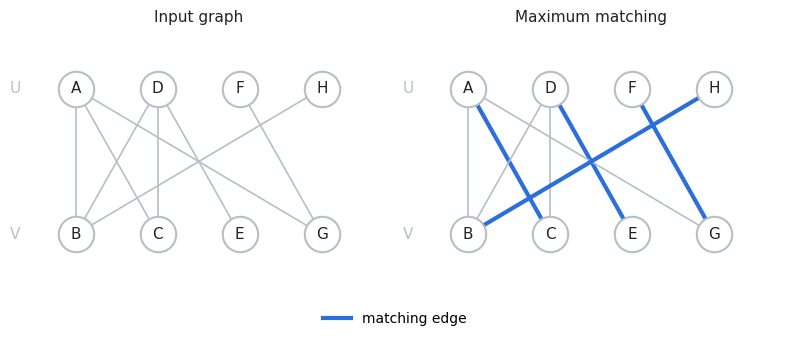

In [ ]:
plot_solution(U, V, edges, [], matching)